In [78]:
from langgraph.graph import StateGraph,START,END
from langchain_cohere import ChatCohere
from dotenv import load_dotenv
from typing import TypedDict,Literal
from pydantic import BaseModel,Field

In [79]:
load_dotenv()
model_name = "command-a-plus-05-2026"
model= ChatCohere(model=model_name)

In [80]:
class SentimentSchema(BaseModel):
    sentiment:Literal["positive","negative"]=Field(description="Sentiment of the review")

In [81]:
class DiagnosisSchema(BaseModel):
    issue_type: Literal["UX", "Performance", "Bug", "Support", "Other"] = Field(description='The category of issue mentioned in the review')
    tone: Literal["angry", "frustrated", "disappointed", "calm"] = Field(description='The emotional tone expressed by the user')
    urgency: Literal["low", "medium", "high"] = Field(description='How urgent or critical the issue appears to be')

In [82]:
structured_model1=model.with_structured_output(SentimentSchema)
structured_model2=model.with_structured_output(DiagnosisSchema)

In [83]:
prompt = 'What is the sentiment of the following review - The software too cool'
structured_model1.invoke(prompt)

SentimentSchema(sentiment='positive')

In [84]:
class state(TypedDict):
    review:str
    sentiment:Literal["positive","negative"]
    diagnosis:dict
    response:str

In [85]:
def findSentiment(state:TypedDict)->dict:
    prompt = f'For the following review find out the sentiment \n {state["review"]}'
    sentiment=structured_model1.invoke(prompt).sentiment
    return {
        "sentiment":sentiment
    }



In [86]:
def checkSentiment(state:TypedDict)->Literal["runDiagnosis","positiveResponse"]:
    if state["sentiment"]=="positive":
        return "positiveResponse"
    return "runDiagnosis"

In [87]:
def runDiagnosis(state:TypedDict)->dict:
     prompt = f"""Diagnose this negative review:\n\n{state['review']}\n" "Return issue_type, tone, and urgency."""
     diagnosis=structured_model2.invoke(prompt)    
     return {
         "diagnosis":diagnosis.model_dump()
     }

In [88]:
def get_text(content):
    # Reasoning models return a list of blocks; keep only the text block(s)
    if isinstance(content, str):
        return content
    return "".join(item["text"] for item in content if item.get("type") == "text")

def positiveResponse(state:TypedDict)->dict:
    prompt = f"""Write a warm thank-you message in response to this review:\n\n\"{state['review']}\"\nAlso, kindly ask the user to leave feedback on our website."""
    response = get_text(model.invoke(prompt).content)

    return {'response': response}

In [89]:
def negativeResponse(state:TypedDict)->dict:
    diagnosis = state['diagnosis']

    prompt = f"""You are a support assistant.The user had a '{diagnosis['issue_type']}' issue, sounded '{diagnosis['tone']}', and marked urgency as '{diagnosis['urgency']}'.Write an empathetic, helpful resolution message."""
    response = get_text(model.invoke(prompt).content)

    return {'response': response}

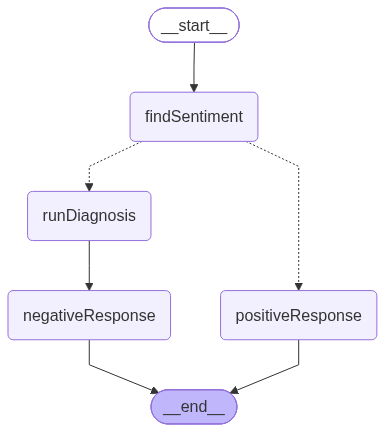

In [90]:
graph=StateGraph(state)
graph.add_node("findSentiment",findSentiment)
graph.add_node("runDiagnosis",runDiagnosis)
graph.add_node("positiveResponse",positiveResponse)
graph.add_node("negativeResponse",negativeResponse)
graph.add_edge(START,"findSentiment")
graph.add_conditional_edges("findSentiment",checkSentiment,{
    "runDiagnosis":"runDiagnosis",
    "positiveResponse":"positiveResponse"
})
graph.add_edge("runDiagnosis","negativeResponse")
graph.add_edge("negativeResponse",END)
graph.add_edge("positiveResponse",END)
workflow=graph.compile()
workflow


In [ ]:
intial_state={
    'review': "I emailed support three times over two weeks about a double charge on my card and nobody has replied. This is outrageous and I want my money back today."
}
final_state=workflow.invoke(intial_state)
print(final_state)

{'review': 'I emailed support three times over two weeks about a double charge on my card and nobody has replied. This is outrageous and I want my money back today.', 'sentiment': 'negative', 'diagnosis': {'issue_type': 'Support', 'tone': 'angry', 'urgency': 'high'}, 'response': '**Subject:** We’re Here for You – Your Issue Is Our Top Priority  \n\nHi\u202f[Customer Name],\n\nI’m truly sorry you’re experiencing this problem, and I completely understand how frustrating and urgent it feels right now. Please know that we take your situation seriously, and I’m personally committed to resolving it as quickly as possible.\n\n**What I’m doing for you right now**\n\n1. **Immediate escalation** – I’ve flagged your case with high priority and added a note to expedite any actions that may be required.  \n2. **Dedicated support line** – If you’d like, I can arrange a direct call with a senior specialist who can work on this in real time. Just let me know a convenient time, and I’ll send a calendar

In [98]:
print(final_state["response"])

**Subject:** We’re Here for You – Your Issue Is Our Top Priority  

Hi [Customer Name],

I’m truly sorry you’re experiencing this problem, and I completely understand how frustrating and urgent it feels right now. Please know that we take your situation seriously, and I’m personally committed to resolving it as quickly as possible.

**What I’m doing for you right now**

1. **Immediate escalation** – I’ve flagged your case with high priority and added a note to expedite any actions that may be required.  
2. **Dedicated support line** – If you’d like, I can arrange a direct call with a senior specialist who can work on this in real time. Just let me know a convenient time, and I’ll send a calendar invite.  
3. **Quick troubleshooting** – While we get deeper into the investigation, please try the following (it often resolves the issue in minutes):  
   - Clear your browser cache and cookies, then restart the browser.  
   - If you’re on a mobile app, try a fresh install or a device resta